# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [7]:
%cd K4-Track-4-Day10-VisionLanguageModel

/content/K4-Track-4-Day10-VisionLanguageModel


In [2]:
# Runtime → Change runtime type → T4 GPU
!nvidia-smi -L
!pip -q install -r requirements-colab.txt

GPU 0: Tesla T4 (UUID: GPU-14265abf-3749-b4ea-b63f-d25e04ea85b4)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 83.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 59.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.0 MB/s eta 0:00:00


In [4]:
# Kaggle credentials: use Colab Secrets; never hard-code credentials.
import os
try:
    from google.colab import userdata
    for key in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
        value = userdata.get(key)
        if value:
            os.environ[key] = value
except (ImportError, ModuleNotFoundError):
    print("Not running in Colab; set KAGGLE_USERNAME and KAGGLE_KEY in the environment if needed.")

## 1. Dữ liệu: tải và chia split

In [8]:
!python scripts/prepare_data.py --kaggle

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:02<00:00, 94.7MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


train: 1422 images, 3515 boxes
val: 276 images, 639 boxes
test: 311 images, 583 boxes
session overlap train/val: 0
session overlap train/test: 0
session overlap val/test: 0


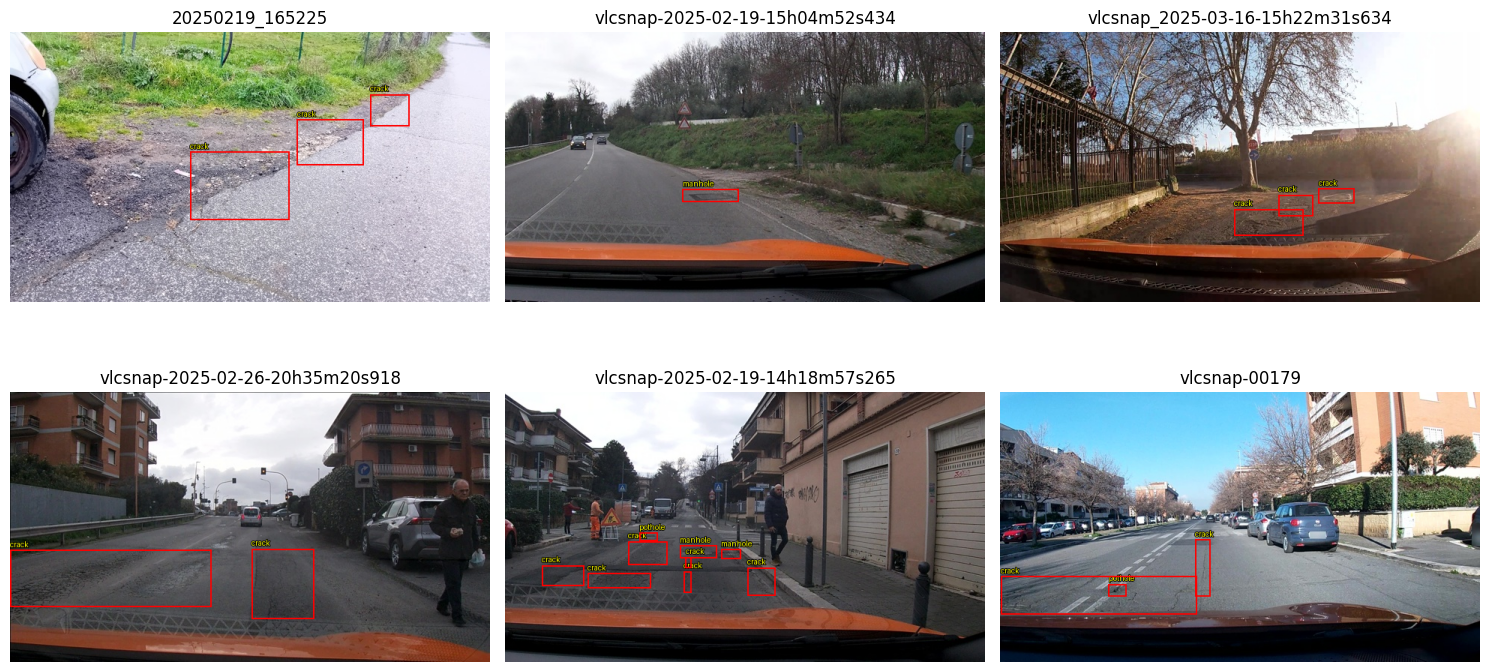

In [9]:
from pathlib import Path
import json, random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

DATA_DIR = Path("data")
SPLIT_DIR = DATA_DIR / "splits"

def read_jsonl(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run the data preparation cell first.")
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

splits = {name: read_jsonl(SPLIT_DIR / f"{name}.jsonl")
          for name in ("train", "val", "test")}
for name, rows in splits.items():
    n_boxes = sum(len(row.get("objects", [])) for row in rows)
    print(f"{name}: {len(rows)} images, {n_boxes} boxes")

# A session must belong to exactly one split to prevent near-duplicate leakage.
sessions_by_split = {
    name: {row.get("session") for row in rows if row.get("session") is not None}
    for name, rows in splits.items()
}
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    overlap = sessions_by_split[a] & sessions_by_split[b]
    print(f"session overlap {a}/{b}: {len(overlap)}")
    assert not overlap, f"Session leakage between {a} and {b}: {list(overlap)[:5]}"

def resolve_image_path(relative_path):
    p = Path(relative_path)
    if p.exists():
        return p
    candidate = DATA_DIR / p
    if candidate.exists():
        return candidate
    raise FileNotFoundError(f"Image not found: {relative_path}")

def draw_sample(row, ax=None):
    image = Image.open(resolve_image_path(row["image_path"])).convert("RGB")
    draw = ImageDraw.Draw(image)
    W, H = image.size
    for obj in row.get("objects", []):
        xc, yc, w, h = obj["yolo"]
        box = ((xc-w/2)*W, (yc-h/2)*H, (xc+w/2)*W, (yc+h/2)*H)
        draw.rectangle(box, outline="red", width=max(2, W//320))
        draw.text((box[0], max(0, box[1]-14)), obj["label"], fill="yellow",
                  stroke_width=1, stroke_fill="black")
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))
    ax.imshow(image)
    ax.axis("off")
    ax.set_title(row.get("image_id", Path(row["image_path"]).name))
    return ax

sample_rows = random.sample(splits["train"], min(6, len(splits["train"])))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, row in zip(axes.flat, sample_rows):
    draw_sample(row, ax)
for ax in axes.flat[len(sample_rows):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

Classes: ('crack', 'manhole', 'pothole')
Prompt: Detect road damage in the image. Allowed classes: crack, manhole, pothole. Return only a JSON list. Each item must have keys "label" and "bbox_2d", where bbox_2d is [x1,y1,x2,y2] on the 0–1000 coordinate scale (0 is the left/top edge and 1000 is the right/bottom edge). Use only the allowed classes. If no damage is visible, return [].
Example answer: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]


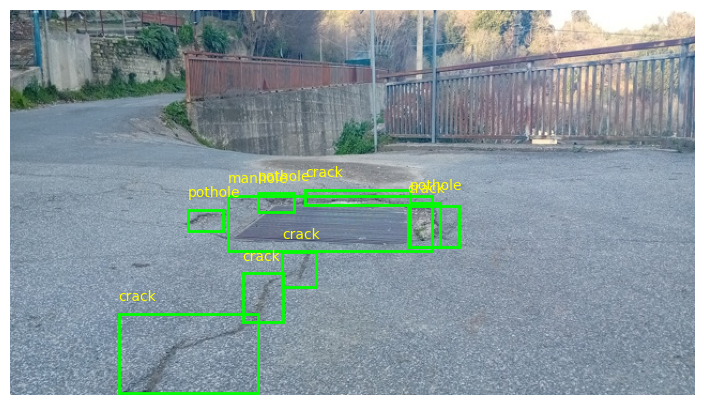

[{'label': 'crack', 'bbox_2d': [430, 467, 583, 506]},
 {'label': 'pothole', 'bbox_2d': [361, 475, 414, 522]},
 {'label': 'manhole', 'bbox_2d': [317, 481, 616, 625]},
 {'label': 'pothole', 'bbox_2d': [583, 500, 627, 614]},
 {'label': 'crack', 'bbox_2d': [580, 508, 655, 614]},
 {'label': 'pothole', 'bbox_2d': [259, 517, 311, 572]},
 {'label': 'crack', 'bbox_2d': [397, 628, 447, 717]},
 {'label': 'crack', 'bbox_2d': [339, 683, 398, 808]},
 {'label': 'crack', 'bbox_2d': [158, 789, 361, 994]}]

In [10]:
import json
from PIL import Image

# Derive the exact class names from the prepared labels instead of assuming them.
CLASSES = tuple(sorted({obj["label"] for row in splits["train"]
                        for obj in row.get("objects", [])}))
if not CLASSES:
    raise ValueError("No training labels found. Check data/splits/train.jsonl.")

PROMPT = (
    "Detect road damage in the image. Allowed classes: " + ", ".join(CLASSES) + ". "
    'Return only a JSON list. Each item must have keys "label" and "bbox_2d", '
    "where bbox_2d is [x1,y1,x2,y2] on the 0–1000 coordinate scale "
    "(0 is the left/top edge and 1000 is the right/bottom edge). "
    "Use only the allowed classes. If no damage is visible, return []."
)

def yolo_to_box(label, yolo):
    if label not in CLASSES:
        raise ValueError(f"Unknown label {label!r}; expected one of {CLASSES}")
    xc, yc, w, h = map(float, yolo)
    coords = [
        round((xc - w / 2) * 1000),
        round((yc - h / 2) * 1000),
        round((xc + w / 2) * 1000),
        round((yc + h / 2) * 1000),
    ]
    coords = [max(0, min(1000, int(v))) for v in coords]
    x1, y1, x2, y2 = coords
    if x2 < x1: x1, x2 = x2, x1
    if y2 < y1: y1, y2 = y2, y1
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects):
    boxes = [yolo_to_box(obj["label"], obj["yolo"]) for obj in objects]
    boxes.sort(key=lambda item: (item["bbox_2d"][1], item["bbox_2d"][0]))
    return json.dumps(boxes, separators=(",", ":"), ensure_ascii=False)

def verify_box_round_trip(row):
    image = Image.open(resolve_image_path(row["image_path"])).convert("RGB")
    W, H = image.size
    answer = json.loads(objects_to_answer(row.get("objects", [])))
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.imshow(image)
    for item in answer:
        x1, y1, x2, y2 = item["bbox_2d"]
        px = [x1*W/1000, y1*H/1000, x2*W/1000, y2*H/1000]
        ax.add_patch(plt.Rectangle((px[0], px[1]), px[2]-px[0], px[3]-px[1],
                                   fill=False, edgecolor="lime", linewidth=2))
        ax.text(px[0], max(0, px[1]-12), item["label"], color="yellow")
    ax.axis("off"); plt.show()
    image.close()
    return answer

print("Classes:", CLASSES)
print("Prompt:", PROMPT)
print("Example answer:", objects_to_answer(splits["train"][0].get("objects", [])))
verify_box_round_trip(splits["train"][0])

## 3. E0: zero-shot

In [20]:
import os, json, time, gc
from pathlib import Path
import torch
from PIL import Image
from tqdm.auto import tqdm

WORK_DIR = Path("work")
EVIDENCE_DIR = Path("report/evidence")
WORK_DIR.mkdir(parents=True, exist_ok=True)
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

# Model loading / inference are expensive; set True when ready to run on a GPU.
RUN_E0 = True
MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"

def load_base_model():
    from transformers import AutoProcessor, BitsAndBytesConfig
    from transformers import Qwen3VLForConditionalGeneration
    if not torch.cuda.is_available():
        raise RuntimeError("Qwen3-VL-4B 4-bit inference requires a CUDA GPU for this lab.")
    quantization = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
        llm_int8_skip_modules=["visual", "lm_head"],
    )
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=quantization, dtype=torch.float16,
        device_map={"": 0},
    )
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    processor.tokenizer.padding_side = "left"
    model.eval()
    return model, processor

def make_user_message(image, prompt=PROMPT):
    return {"role": "user", "content": [
        {"type": "image", "image": image},
        {"type": "text", "text": prompt},
    ]}

@torch.inference_mode()
def predict_rows(model, processor, rows, output_path, batch_size=4, max_new_tokens=256):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with output_path.open("w", encoding="utf-8") as out_f:
        for start in tqdm(range(0, len(rows), batch_size), desc=output_path.name):
            batch = rows[start:start+batch_size]
            images = [Image.open(resolve_image_path(r["image_path"])).convert("RGB") for r in batch]
            messages = [make_user_message(img) for img in images]
            inputs = processor.apply_chat_template(
                messages, tokenize=True, add_generation_prompt=True,
                return_dict=True, return_tensors="pt", padding=True,
            )
            inputs = {k: (v.to(model.device) if torch.is_tensor(v) else v)
                      for k, v in inputs.items()}
            generated = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
            prompt_len = inputs["input_ids"].shape[1]
            decoded = processor.batch_decode(generated[:, prompt_len:],
                                              skip_special_tokens=True)
            for row, raw in zip(batch, decoded):
                out_f.write(json.dumps({"image_id": row["image_id"], "raw": raw},
                                       ensure_ascii=False) + "\n")
            for image in images:
                image.close()
    return output_path

if RUN_E0:
    model, processor = load_base_model()
    e0_path = predict_rows(model, processor, splits["test"], WORK_DIR / "e0.jsonl")
    print(f"Saved {e0_path}; first outputs:")
    for i, line in enumerate(e0_path.open(encoding="utf-8")):
        if i >= 5:
            break
        print(line.rstrip())
    del model, processor
    gc.collect(); torch.cuda.empty_cache()
else:
    print("E0 is implemented but not run. Set RUN_E0=True and execute this cell on a CUDA runtime.")

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

e0.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

Saved work/e0.jsonl; first outputs:
{"image_id": "vlcsnap-00200", "raw": "[{\"label\": \"crack\", \"bbox_2d\": [359, 657, 500, 700]}]"}
{"image_id": "vlcsnap-00204", "raw": "[{\"label\": \"crack\", \"bbox_2d\": [12, 650, 1000, 700]}]"}
{"image_id": "vlcsnap-00208", "raw": "[{\"label\": \"crack\", \"bbox_2d\": [559, 672, 675, 700]}]"}
{"image_id": "vlcsnap-00212", "raw": "[{\"label\": \"crack\", \"bbox_2d\": [10, 550, 1000, 700]}]"}
{"image_id": "vlcsnap-2025-02-18-23h07m46s200", "raw": "[{\"label\": \"crack\", \"bbox_2d\": [359, 450, 500, 500]}]"}


In [31]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

E0 [test] n=311 valid=0.225 P=0.057 R=0.009 F1=0.015 CI95=0.003-0.029 meanIoU=0.570 FP/img=0.26
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.042 R=0.010 F1=0.016
   manhole  P=0.182 R=0.012 F1=0.023


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [38]:
import torch
from torch.nn.utils.rnn import pad_sequence

def encode_example(image, prompt, answer, processor):
    user = make_user_message(image, prompt)
    prompt_enc = processor.apply_chat_template(
        [user], tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt",
    )
    full_enc = processor.apply_chat_template(
        [user, {"role": "assistant", "content": answer}],
        tokenize=True, add_generation_prompt=False,
        return_dict=True, return_tensors="pt",
    )
    n = prompt_enc["input_ids"].shape[1]
    if not torch.equal(full_enc["input_ids"][0, :n], prompt_enc["input_ids"][0]):
        raise ValueError("Prompt token sequence is not a prefix of the full conversation.")
    result = {k: v for k, v in full_enc.items()}
    result["labels"] = full_enc["input_ids"].clone()
    result["labels"][:, :n] = -100
    return result

def collate_examples(batch, processor):
    # Text-like sequences are padded; image tensors/grid metadata are concatenated.
    pad_id = processor.tokenizer.pad_token_id
    if pad_id is None:
        pad_id = processor.tokenizer.eos_token_id
    sequence_keys = ("input_ids", "attention_mask", "mm_token_type_ids", "labels")
    result = {}
    max_len = max(item["input_ids"].shape[1] for item in batch)
    for key in sequence_keys:
        if not all(key in item for item in batch):
            continue
        tensors = []
        for item in batch:
            x = item[key].squeeze(0)
            pad_value = -100 if key == "labels" else (pad_id if key == "input_ids" else 0)
            if x.shape[0] < max_len:
                x = torch.nn.functional.pad(x, (0, max_len-x.shape[0]), value=pad_value)
            tensors.append(x)
        result[key] = torch.stack(tensors)
    for key in ("pixel_values", "image_grid_thw"):
        vals = [item[key] for item in batch if key in item]
        if vals:
            result[key] = torch.cat(vals, dim=0)
    return result

# Smoke-check one encoded example after the processor is loaded.
print("Encoding/collation functions defined. Run after loading the processor/model.")

Encoding/collation functions defined. Run after loading the processor/model.


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [39]:
import re
import torch
from peft import LoraConfig, get_peft_model

# Language-model targets: 36 layers × 7 modules = 252
LLM_PATTERN = re.compile(
    r"model\.language_model\.layers\.\d+\."
    r"(?:self_attn\.(?:q_proj|k_proj|v_proj|o_proj)|"
    r"mlp\.(?:gate_proj|up_proj|down_proj))$"
)

# Vision targets: 24 blocks × 4 modules = 96
VIT_PATTERN = re.compile(
    r"model\.visual\.blocks\.\d+\."
    r"(?:attn\.(?:qkv|proj)|"
    r"mlp\.(?:linear_fc1|linear_fc2))$"
)

PROJECTOR_MARKERS = (
    "visual.merger",
    "visual.deepstack_merger_list",
)


def apply_setup(model, setup, r=16):
    setup = setup.upper()

    if setup not in {"E1", "E2", "E3"}:
        raise ValueError("setup must be E1, E2, or E3")

    # 1. Freeze all original model parameters.
    for param in model.parameters():
        param.requires_grad_(False)

    # Required for gradient checkpointing with frozen base weights.
    if hasattr(model, "enable_input_require_grads"):
        model.enable_input_require_grads()

    # 2. Validate the actual model module names.
    names = [name for name, _ in model.named_modules()]

    matched_llm = [
        name for name in names
        if LLM_PATTERN.fullmatch(name)
    ]

    matched_vit = (
        [
            name for name in names
            if VIT_PATTERN.fullmatch(name)
        ]
        if setup == "E3"
        else []
    )

    matched = matched_llm + matched_vit
    expected = 348 if setup == "E3" else 252

    print(
        f"{setup}: matched {len(matched)} target modules "
        f"(expected {expected})"
    )

    if len(matched) != expected:
        relevant = [
            name for name in names
            if "language_model.layers" in name
            or "visual.blocks" in name
        ]
        print("\nRelevant module names:")
        print("\n".join(relevant[:100]))

        raise ValueError(
            f"{setup}: expected {expected} target modules, "
            f"but found {len(matched)}. No LoRA adapters were added."
        )

    # 3. Configure LoRA targets.
    llm_targets = (
        r".*model\.language_model\.layers\.\d+\."
        r"(?:self_attn\.(?:q_proj|k_proj|v_proj|o_proj)|"
        r"mlp\.(?:gate_proj|up_proj|down_proj))"
    )

    if setup == "E3":
        target_modules = (
            r"(?:"
            + llm_targets
            + r"|.*model\.visual\.blocks\.\d+\."
            r"(?:attn\.(?:qkv|proj)|"
            r"mlp\.(?:linear_fc1|linear_fc2))"
            + r")"
        )
    else:
        target_modules = llm_targets

    peft_model = get_peft_model(
        model,
        LoraConfig(
            r=r,
            lora_alpha=2 * r,
            lora_dropout=0.05,
            bias="none",
            target_modules=target_modules,
            task_type="CAUSAL_LM",
        ),
    )

    # 4. E2/E3: train the visual projectors in FP32.
    # E1 leaves these parameters frozen.
    projector_params = []

    if setup in {"E2", "E3"}:
        for name, param in peft_model.named_parameters():
            if any(marker in name for marker in PROJECTOR_MARKERS):
                param.data = param.data.float()
                param.requires_grad_(True)
                projector_params.append(name)

        if not projector_params:
            raise RuntimeError(
                f"{setup}: no projector parameters matched "
                f"{PROJECTOR_MARKERS}. Inspect named_parameters() "
                "before training."
            )

        non_fp32 = [
            name for name, param in peft_model.named_parameters()
            if any(marker in name for marker in PROJECTOR_MARKERS)
            and param.requires_grad
            and param.dtype != torch.float32
        ]

        if non_fp32:
            raise RuntimeError(
                "Some trainable projector parameters are not FP32: "
                + ", ".join(non_fp32[:10])
            )

        print(
            f"Trainable projector parameter tensors: "
            f"{len(projector_params)}"
        )

    # 4.5. Keep all trainable parameters in FP32.
    # Frozen base-model weights retain their original dtype.
    for name, param in peft_model.named_parameters():
        if param.requires_grad and param.dtype != torch.float32:
            param.data = param.data.float()

    # Verify the trainable parameter dtypes.
    non_fp32_trainable = [
        (name, str(param.dtype))
        for name, param in peft_model.named_parameters()
        if param.requires_grad and param.dtype != torch.float32
    ]

    if non_fp32_trainable:
        raise RuntimeError(
            "Found trainable parameters that are not FP32: "
            + ", ".join(
                f"{name} ({dtype})"
                for name, dtype in non_fp32_trainable[:10]
            )
        )

    # 5. Report trainable parameter count and dtype distribution.
    trainable = sum(
        param.numel()
        for param in peft_model.parameters()
        if param.requires_grad
    )

    total = sum(
        param.numel()
        for param in peft_model.parameters()
    )

    trainable_dtypes = {}
    for param in peft_model.parameters():
        if param.requires_grad:
            key = str(param.dtype)
            trainable_dtypes[key] = (
                trainable_dtypes.get(key, 0) + param.numel()
            )

    print("Trainable parameter dtypes:", trainable_dtypes)
    print(
        f"Trainable parameters: {trainable:,} / {total:,} "
        f"({100 * trainable / total:.4f}%)"
    )

    return peft_model, {
        "matched_modules": len(matched),
        "trainable_params": trainable,
    }

## 6. Vòng huấn luyện

In [41]:
import math, time, json, gc, copy
from pathlib import Path
import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

TRAIN_CONFIG = {
    "max_steps": 300, "batch_size": 2, "grad_accum": 4,
    "learning_rate": 2e-4, "weight_decay": 0.0, "warmup_ratio": 0.05,
    "save_every": 100, "max_grad_norm": 1.0, "num_workers": 0,
}
RUN_TRAINING = True  # Set True after confirming GPU memory and data availability.

class RoadDamageDataset(Dataset):
    def __init__(self, rows, processor):
        self.rows = rows
        self.processor = processor

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        image = Image.open(resolve_image_path(row["image_path"])).convert("RGB")
        try:
            answer = objects_to_answer(row.get("objects", []))
            encoded = encode_example(image, PROMPT, answer, self.processor)
        finally:
            image.close()
        return encoded

def save_projector_weights(model, path):
    state = {name: p.detach().float().cpu()
             for name, p in model.named_parameters()
             if any(marker in name for marker in PROJECTOR_MARKERS)}
    torch.save(state, path)

def train_setup(setup, model, processor, train_rows, config=TRAIN_CONFIG, rank=16):
    setup_dir = Path("work") / setup.lower()
    setup_dir.mkdir(parents=True, exist_ok=True)
    peft_model, info = apply_setup(model, setup, r=rank)
    peft_model.config.use_cache = False
    try:
        peft_model.gradient_checkpointing_enable(
            gradient_checkpointing_kwargs={"use_reentrant": False}
        )
    except TypeError:
        peft_model.gradient_checkpointing_enable()

    dataset = RoadDamageDataset(train_rows, processor)
    loader = DataLoader(
        dataset, batch_size=config["batch_size"], shuffle=True,
        collate_fn=lambda batch: collate_examples(batch, processor),
        num_workers=config["num_workers"],
    )
    trainable_params = [p for p in peft_model.parameters() if p.requires_grad]
    optimizer = AdamW(trainable_params, lr=config["learning_rate"],
                      weight_decay=config["weight_decay"])
    max_steps = config["max_steps"]
    warmup_steps = max(1, int(max_steps * config["warmup_ratio"]))
    def lr_lambda(step):
        if step < warmup_steps:
            return max(1e-8, (step + 1) / warmup_steps)
        progress = min(1.0, (step - warmup_steps) / max(1, max_steps - warmup_steps))
        return 0.5 * (1.0 + math.cos(math.pi * progress))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = torch.amp.GradScaler("cuda", enabled=(torch.cuda.is_available()))
    device = next(peft_model.parameters()).device
    peft_model.train()
    optimizer.zero_grad(set_to_none=True)
    step, micro_step, running_loss = 0, 0, 0.0
    losses, start_time = [], time.time()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    while step < max_steps:
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16,
                                enabled=torch.cuda.is_available()):
                loss = peft_model(**batch).loss
                scaled_loss = loss / config["grad_accum"]
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss at optimizer step {step}: {loss.item()}")
            scaler.scale(scaled_loss).backward()
            running_loss += float(loss.detach())
            micro_step += 1
            if micro_step % config["grad_accum"] != 0:
                continue
            fp16_grads = [
                name for name, param in peft_model.named_parameters()
                if param.requires_grad and param.grad is not None
                and param.grad.dtype == torch.float16
            ]
            if fp16_grads:
                raise RuntimeError(
                    "FP16 gradients found before scaler.unscale_(). "
                    "Affected parameters: " + ", ".join(fp16_grads[:20])
                )

            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_params, config["max_grad_norm"])
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True); scheduler.step()
            step += 1
            mean_loss = running_loss / config["grad_accum"]
            losses.append({"step": step, "loss": mean_loss, "lr": scheduler.get_last_lr()[0]})
            running_loss = 0.0
            if step % 10 == 0:
                print(f"{setup} step {step}/{max_steps} loss={mean_loss:.4f}")
            if step % config["save_every"] == 0 or step == max_steps:
                ckpt = setup_dir / f"checkpoint-{step}"
                ckpt.mkdir(exist_ok=True)
                peft_model.save_pretrained(ckpt)
                if setup in {"E2", "E3"}:
                    save_projector_weights(peft_model, ckpt / "extra_trainable.pt")
                with (ckpt / "losses.json").open("w") as f:
                    json.dump(losses, f, indent=2)
            if step >= max_steps:
                break
    elapsed = (time.time() - start_time) / 60
    peak_vram = torch.cuda.max_memory_allocated() / (1024**3) if torch.cuda.is_available() else 0.0
    run_info = {**info, "setup": setup, "trainable_params": info["trainable_params"],
                "peak_vram_gb": round(peak_vram, 3), "train_minutes": round(elapsed, 2),
                "steps": step, "final_loss": losses[-1]["loss"] if losses else None}
    (setup_dir / "run.json").write_text(json.dumps(run_info, indent=2), encoding="utf-8")
    peft_model.save_pretrained(setup_dir / "final")
    if setup in {"E2", "E3"}:
        save_projector_weights(peft_model, setup_dir / "final" / "extra_trainable.pt")
    return peft_model, run_info, losses

def run_one_setup(setup_name):
    """Train only one setup from a fresh base-model instance."""
    base_model = None
    trained_model = None
    try:
        base_model, processor = load_base_model()
        trained_model, run_info, losses = train_setup(
            setup_name, base_model, processor, splits["train"]
        )
        return run_info, losses
    finally:
        del trained_model
        del base_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# The former combined E1/E2/E3 runner is intentionally disabled.
# Do not uncomment this loop: run the individual setup cells below instead.
# for setup_name in ("E1", "E2", "E3"):
#     run_one_setup(setup_name)


### Train E1

Run only when you intentionally want to train or retrain E1.

In [ ]:
# Train E1 ONLY. This loads a fresh base model and runs E1 for 300 optimizer steps.
# Run this cell only if you intend to train/retrain E1.
E1_result, E1_losses = run_one_setup("E1")
print("E1 completed:", E1_result)

### E1 — Check existing results

This cell only inspects saved E1 metadata, checkpoints, adapters, projector weights, and loss history. It does not load the base model or train.

In [45]:

from pathlib import Path
import json

setup_dir = Path("work/e1")
run_file = setup_dir / "run.json"
print("E1 saved-run check")

if not run_file.exists():
    print(f"No saved E1 run metadata found at {run_file}.")
    print("This cell does not train or modify any model.")
else:
    result = json.loads(run_file.read_text(encoding="utf-8"))
    print("Run metadata:")
    print(json.dumps(result, indent=2))

    for step in (100, 200, 300):
        ckpt = setup_dir / f"checkpoint-{step}"
        print(f"\nCheckpoint {step}: {'present' if ckpt.exists() else 'missing'}")
        if ckpt.exists():
            print(f"  adapter config: {(ckpt / 'adapter_config.json').exists()}")

    final_dir = setup_dir / "final"
    print(f"\nFinal adapter directory: {'present' if final_dir.exists() else 'missing'}")
    print(f"Final adapter config: {(final_dir / 'adapter_config.json').exists()}")

    loss_file = setup_dir / "checkpoint-300" / "losses.json"
    if loss_file.exists():
        losses = json.loads(loss_file.read_text(encoding="utf-8"))
        print(f"\nSaved loss records: {len(losses)}")
        if losses:
            print(f"First loss: {losses[0]}")
            print(f"Last loss:  {losses[-1]}")

            print("\nE1 loss history (every 10 steps):")
            for item in losses:
                if item["step"] % 10 == 0:
                    print(f"E1 step {item['step']}/300 loss={item['loss']:.4f}")
    else:
        print(f"\nLoss history not found at {loss_file}.")

E1 saved-run check
Run metadata:
{
  "matched_modules": 252,
  "trainable_params": 33030144,
  "setup": "E1",
  "peak_vram_gb": 7.932,
  "train_minutes": 48.62,
  "steps": 300,
  "final_loss": 0.5879627615213394
}

Checkpoint 100: present
  adapter config: True

Checkpoint 200: present
  adapter config: True

Checkpoint 300: present
  adapter config: True

Final adapter directory: present
Final adapter config: True

Saved loss records: 300
First loss: {'step': 1, 'loss': 1.0299763232469559, 'lr': 2.6666666666666667e-05}
Last loss:  {'step': 300, 'loss': 0.5879627615213394, 'lr': 0.0}

E1 loss history (every 10 steps):
E1 step 10/300 loss=0.7841
E1 step 20/300 loss=0.7159
E1 step 30/300 loss=0.6248
E1 step 40/300 loss=0.5742
E1 step 50/300 loss=0.6624
E1 step 60/300 loss=0.6521
E1 step 70/300 loss=0.6070
E1 step 80/300 loss=0.6244
E1 step 90/300 loss=0.5715
E1 step 100/300 loss=0.6520
E1 step 110/300 loss=0.6726
E1 step 120/300 loss=0.6384
E1 step 130/300 loss=0.6227
E1 step 140/300 los

### Train E2

Run only when you intentionally want to train or retrain E2.

In [ ]:
# Train E2 ONLY. This loads a fresh base model and runs E2 for 300 optimizer steps.
# Run this cell only if you intend to train/retrain E2.
E2_result, E2_losses = run_one_setup("E2")
print("E2 completed:", E2_result)

### E2 — Check existing results

This cell only inspects saved E2 metadata, checkpoints, adapters, projector weights, and loss history. It does not load the base model or train.

In [ ]:

from pathlib import Path
import json

setup_dir = Path("work/e2")
run_file = setup_dir / "run.json"
print("E2 saved-run check")

if not run_file.exists():
    print(f"No saved E2 run metadata found at {run_file}.")
    print("This cell does not train or modify any model.")
else:
    result = json.loads(run_file.read_text(encoding="utf-8"))
    print("Run metadata:")
    print(json.dumps(result, indent=2))

    for step in (100, 200, 300):
        ckpt = setup_dir / f"checkpoint-{step}"
        print(f"\nCheckpoint {step}: {'present' if ckpt.exists() else 'missing'}")
        if ckpt.exists():
            print(f"  adapter config: {(ckpt / 'adapter_config.json').exists()}")
            print(f"  projector weights: {(ckpt / 'extra_trainable.pt').exists()}")

    final_dir = setup_dir / "final"
    print(f"\nFinal adapter directory: {'present' if final_dir.exists() else 'missing'}")
    print(f"Final adapter config: {(final_dir / 'adapter_config.json').exists()}")
    print(f"Final projector weights: {(final_dir / 'extra_trainable.pt').exists()}")

    loss_file = setup_dir / "checkpoint-300" / "losses.json"
    if loss_file.exists():
        losses = json.loads(loss_file.read_text(encoding="utf-8"))
        print(f"\nSaved loss records: {len(losses)}")
        if losses:
            print(f"First loss: {losses[0]}")
            print(f"Last loss:  {losses[-1]}")

            print("\nE2 loss history (every 10 steps):")
            for item in losses:
                if item["step"] % 10 == 0:
                    print(f"E2 step {item['step']}/300 loss={item['loss']:.4f}")
    else:
        print(f"\nLoss history not found at {loss_file}.")

### Train E3

Run only when you intentionally want to train or retrain E3.

In [ ]:
# Train E3 ONLY. This loads a fresh base model and runs E3 for 300 optimizer steps.
# Run this cell only if you intend to train/retrain E3.
E3_result, E3_losses = run_one_setup("E3")
print("E3 completed:", E3_result)

### E3 — Check existing results

This cell only inspects saved E3 metadata, checkpoints, adapters, projector weights, and loss history. It does not load the base model or train.

In [ ]:

from pathlib import Path
import json

setup_dir = Path("work/e3")
run_file = setup_dir / "run.json"
print("E3 saved-run check")

if not run_file.exists():
    print(f"No saved E3 run metadata found at {run_file}.")
    print("This cell does not train or modify any model.")
else:
    result = json.loads(run_file.read_text(encoding="utf-8"))
    print("Run metadata:")
    print(json.dumps(result, indent=2))

    for step in (100, 200, 300):
        ckpt = setup_dir / f"checkpoint-{step}"
        print(f"\nCheckpoint {step}: {'present' if ckpt.exists() else 'missing'}")
        if ckpt.exists():
            print(f"  adapter config: {(ckpt / 'adapter_config.json').exists()}")
            print(f"  projector weights: {(ckpt / 'extra_trainable.pt').exists()}")

    final_dir = setup_dir / "final"
    print(f"\nFinal adapter directory: {'present' if final_dir.exists() else 'missing'}")
    print(f"Final adapter config: {(final_dir / 'adapter_config.json').exists()}")
    print(f"Final projector weights: {(final_dir / 'extra_trainable.pt').exists()}")

    loss_file = setup_dir / "checkpoint-300" / "losses.json"
    if loss_file.exists():
        losses = json.loads(loss_file.read_text(encoding="utf-8"))
        print(f"\nSaved loss records: {len(losses)}")
        if losses:
            print(f"First loss: {losses[0]}")
            print(f"Last loss:  {losses[-1]}")

            print("\nE3 loss history (every 10 steps):")
            for item in losses:
                if item["step"] % 10 == 0:
                    print(f"E3 step {item['step']}/300 loss={item['loss']:.4f}")
    else:
        print(f"\nLoss history not found at {loss_file}.")

## 7. Suy luận và chấm E1–E3

In [ ]:
from peft import PeftModel

RUN_E123_INFERENCE = True  # Set True after training checkpoints exist.

def load_trained_setup(setup, checkpoint="final"):
    base_model, proc = load_base_model()
    adapter_dir = Path("work") / setup.lower() / checkpoint
    if not adapter_dir.exists():
        raise FileNotFoundError(f"Adapter checkpoint not found: {adapter_dir}")
    tuned = PeftModel.from_pretrained(base_model, adapter_dir, is_trainable=False)
    extra_path = adapter_dir / "extra_trainable.pt"
    if extra_path.exists():
        extra = torch.load(extra_path, map_location="cpu", weights_only=True)
        current = dict(tuned.named_parameters())
        missing = [name for name in extra if name not in current]
        if missing:
            raise KeyError(f"Projector parameters missing when restoring: {missing[:5]}")
        with torch.no_grad():
            for name, tensor in extra.items():
                current[name].copy_(tensor.to(device=current[name].device, dtype=current[name].dtype))
    tuned.eval()
    return tuned, proc

if RUN_E123_INFERENCE:
    for setup_name in ("E1", "E2", "E3"):
        tuned_model, tuned_processor = load_trained_setup(setup_name)
        # predict_rows uses the global processor; set it to the matching processor.
        processor = tuned_processor
        pred_path = predict_rows(tuned_model, processor, splits["test"],
                                 WORK_DIR / f"{setup_name.lower()}.jsonl")
        run_meta_path = Path("work") / setup_name.lower() / "run.json"
        meta = json.loads(run_meta_path.read_text()) if run_meta_path.exists() else {}
        import subprocess, sys
        cmd = [sys.executable, "scripts/score.py", "--pred", str(pred_path),
               "--name", setup_name, "--out", f"report/evidence/{setup_name.lower()}.json",
               "--meta", f"trainable_params={meta.get('trainable_params', 0)}",
               "--meta", f"peak_vram_gb={meta.get('peak_vram_gb', 0)}",
               "--meta", f"train_minutes={meta.get('train_minutes', 0)}"]
        subprocess.run(cmd, check=True)
        del tuned_model; gc.collect(); torch.cuda.empty_cache()
else:
    print("E1–E3 inference/scoring is implemented. Set RUN_E123_INFERENCE=True after training.")

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [ ]:
# E4: choose ONE variable and run both values from otherwise identical settings.
# E5: reward function and unit tests are GPU-independent. Full GRPO is optional.
E4_VARIABLE = "rank"  # one of: rank, data_size, coord_scale
E4_VALUES = {"rank": [4, 64], "data_size": [0.1, 1.0],
             "coord_scale": ["norm1000", "pixel"]}
print("E4 plan:", E4_VARIABLE, E4_VALUES[E4_VARIABLE])
print("For each value, retrain from the same base model and save its score JSON as")
print("report/evidence/e4_<variable>_<value>.json. Change only this variable.")

def box_iou_xyxy(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    ix1, iy1, ix2, iy2 = max(ax1,bx1), max(ay1,by1), min(ax2,bx2), min(ay2,by2)
    inter = max(0, ix2-ix1) * max(0, iy2-iy1)
    area_a = max(0, ax2-ax1) * max(0, ay2-ay1)
    area_b = max(0, bx2-bx1) * max(0, by2-by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

def reward(completion, gt_boxes):
    # gt_boxes and parsed boxes use {"label": ..., "bbox_2d": [x1,y1,x2,y2]}.
    try:
        from scripts.score import parse_output
        pred = parse_output(completion)
    except Exception:
        pred = None
    if pred is None:
        return 0.0
    if not gt_boxes and not pred:
        return 1.0
    candidates = []
    for pi, p in enumerate(pred):
        for gi, g in enumerate(gt_boxes):
            if p.get("label") != g.get("label"):
                continue
            iou = box_iou_xyxy(p.get("bbox_2d", []), g.get("bbox_2d", []))
            if iou >= 0.5:
                candidates.append((iou, pi, gi))
    candidates.sort(reverse=True)
    used_p, used_g, total_iou = set(), set(), 0.0
    for iou, pi, gi in candidates:
        if pi not in used_p and gi not in used_g:
            used_p.add(pi); used_g.add(gi); total_iou += iou
    return 0.2 + 0.8 * total_iou / max(len(gt_boxes), len(pred), 1)

# Unit tests for key reward cases. parse_output's accepted schema comes from scripts/score.py.
def test_reward_contract():
    gt = [{"label": CLASSES[0], "bbox_2d": [100,100,300,300]}]
    perfect = json.dumps(gt)
    assert reward(perfect, gt) >= 0.99
    assert reward("not JSON", gt) == 0.0
    wrong_class = [{"label": "__wrong_class__", "bbox_2d": [100,100,300,300]}]
    assert reward(json.dumps(wrong_class), gt) == 0.2
    assert reward("[]", []) == 1.0
    extra = gt + [{"label": CLASSES[0], "bbox_2d": [600,600,900,900]}]
    assert reward(json.dumps(extra), gt) < reward(perfect, gt)
    print("Reward tests passed (assuming scripts.score.parse_output returns list or None).")

test_reward_contract()

## Kết quả và giới hạn khi chạy

Các ô mã đã được điền cho các bước đọc dữ liệu, chuyển nhãn, suy luận zero-shot, mã hoá/mask loss, setup LoRA, huấn luyện, lưu/nạp projector, chấm điểm và reward thử nghiệm. Các bước tải model, suy luận và huấn luyện được bảo vệ bằng các cờ `RUN_*` để tránh tự động tiêu tốn GPU/Colab quota.

Sau khi chạy trên đúng môi trường và dữ liệu của lab, dùng `report/evidence/*.json` và `work/*/run.json` để điền báo cáo. Không thể điền trung thực F1, CI95, VRAM hay thời gian trước khi các lần chạy thực tế hoàn tất. Tên lớp được lấy từ nhãn trong `train.jsonl` thay vì đoán.